# Practical 8 mini-project - key-fob communication chain (report notebook)

**Chain:** source → sampling → 8-bit PCM → packet (ID, rolling code, CRC) → Manchester → OOK → path loss / fading / AWGN → sync + non-coherent demodulation → decoding → reconstruction.

This notebook re-runs the individual stages live (single packet) and shows the saved figures and Monte-Carlo tables produced by `main.py`.
Run `python main.py` first (it creates `figures/` and `results/`); the full written report is `report.pdf`.

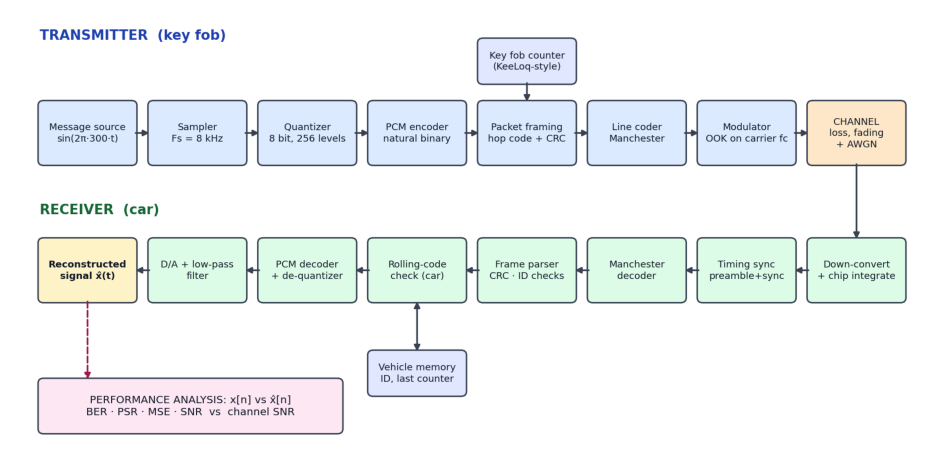

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "functions").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from functions.config import Config
from functions import metrics as mt
from functions.rolling_code import KeyFob, CMD_UNLOCK
from functions.transmitter import transmit
from functions.link import run_link
from functions.analysis import decode_payload

cfg = Config()
rng = np.random.default_rng(cfg.seed)
M = json.loads((ROOT / "results" / "metrics.json").read_text())

def show(name, width=11):
    img = plt.imread(ROOT / "figures" / name)
    plt.figure(figsize=(width, width * img.shape[0] / img.shape[1]))
    plt.imshow(img); plt.axis("off"); plt.show()

show("01_block_diagram.png", 12)

## 1. Source, sampling, quantization and PCM
300 Hz sine, 50 ms, `Fs = 8 kHz` → 400 samples; uniform mid-rise quantizer with 256 levels; natural-binary PCM (MSB first).

samples            : 400
PCM bits           : 3200
quantizer step     : 0.00781
quantization MSE   : 6.314e-06
SQNR measured      : 48.99 dB   (theory 6.02n+1.76 = 49.92 dB)
first code words   : ['10000000', '10011101', '10111010', '11010011']


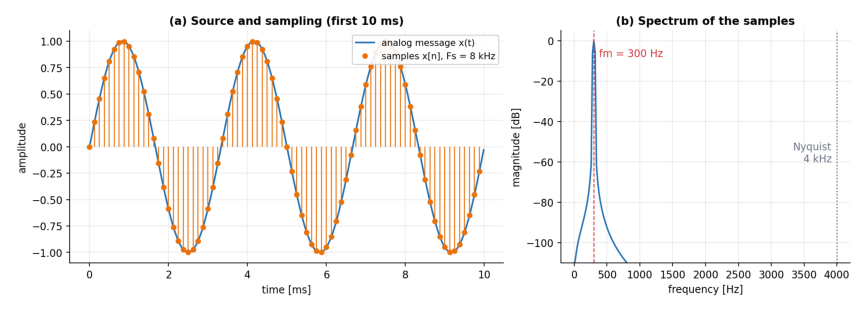

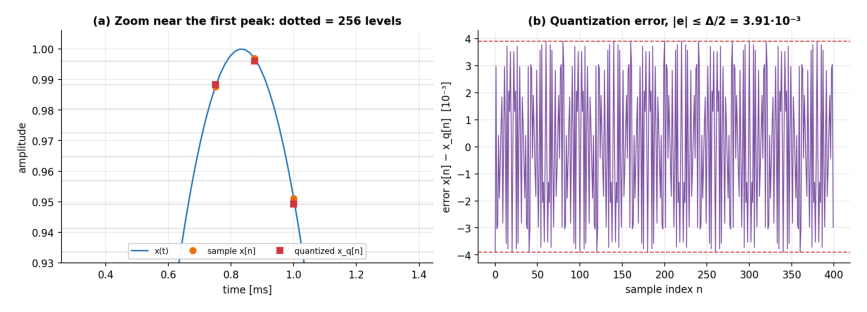

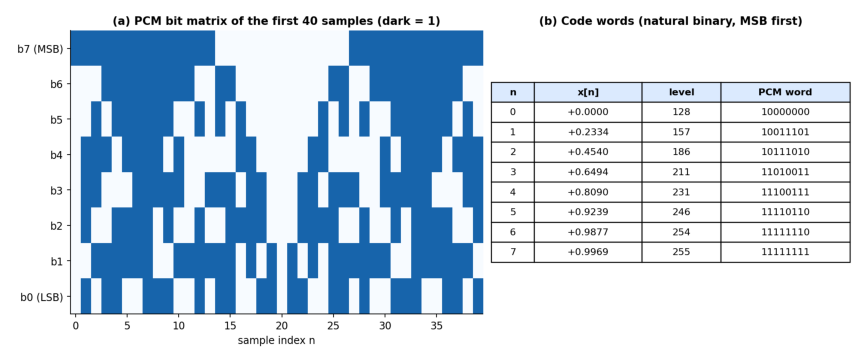

In [3]:
fob = KeyFob(cfg.device_id, cfg.fob_key)
tx = transmit(cfg, fob, CMD_UNLOCK)            # runs source -> ... -> modulated burst
p_x = np.mean(tx.x_s ** 2); mse_q = np.mean((tx.x_s - tx.x_q) ** 2)
print(f"samples            : {tx.x_s.size}")
print(f"PCM bits           : {tx.pcm_bits.size}")
print(f"quantizer step     : {tx.delta:.5f}")
print(f"quantization MSE   : {mse_q:.3e}")
print(f"SQNR measured      : {10*np.log10(p_x/mse_q):.2f} dB   (theory 6.02n+1.76 = {mt.sqnr_theory_db(8):.2f} dB)")
print("first code words   :", ["".join(map(str, w)) for w in tx.pcm_bits.reshape(-1, 8)[:4]])
show("02_source_sampling.png"); show("03_quantization.png"); show("04_pcm_encoding.png")

## 2. Packet framing, line coding and OOK modulation
`[preamble 16][sync 16][device ID 32][command 8][rolling code 32][PCM payload 3200][CRC-16]` = 3320 bits, sent Manchester-coded at 9.6 kbit/s on an OOK carrier.

packet bits        : 3320 -> 6640 Manchester chips -> 106240 samples
airtime            : 345.8 ms
burst power        : 0.2500   (theory A^2/4 = 0.25)
rolling code       : command=0x02, hop=0x56D5A05F, counter=1


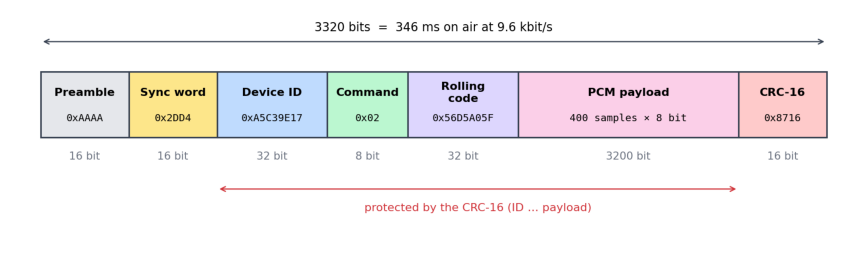

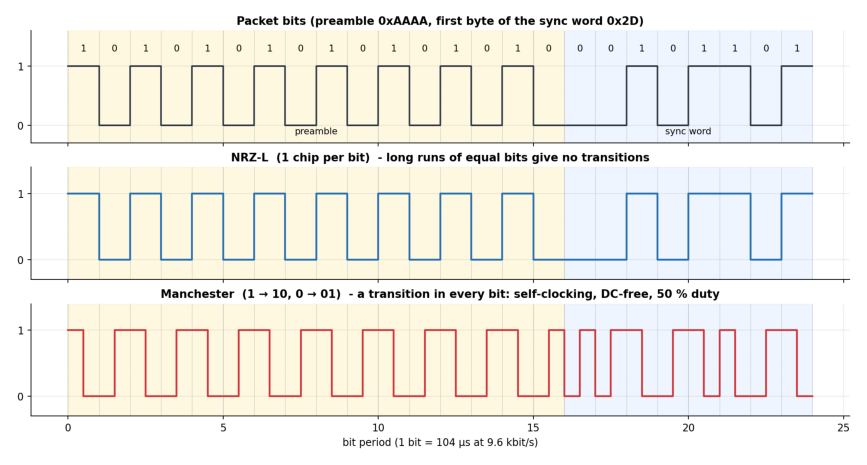

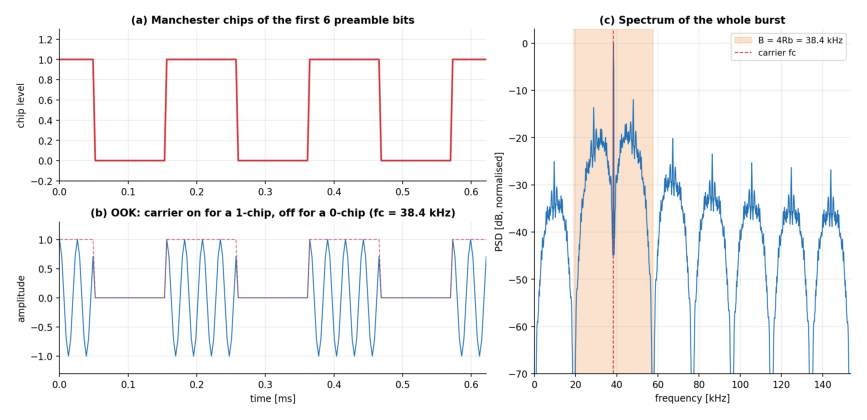

In [5]:
print("packet bits        :", tx.packet_bits.size, "->", tx.chips.size, "Manchester chips ->", tx.burst.size, "samples")
print(f"airtime            : {tx.packet_bits.size / cfg.bit_rate * 1e3:.1f} ms")
print(f"burst power        : {np.mean(tx.burst**2):.4f}   (theory A^2/4 = 0.25)")
print(f"rolling code       : command=0x{tx.command:02X}, hop=0x{tx.hop:08X}, counter={tx.counter}")
show("05_packet_structure.png"); show("06_line_coding.png"); show("07_ook_modulation.png")

## 3. Channel, demodulation and decoding (one packet at SNR = +2 dB and one at -3 dB)
SNR is defined like MATLAB `awgn(x, SNR, 'measured')`; Eb/N0 = SNR + 12.04 dB.

SNR +2 dB: true start 237, estimated 237, bit errors 0, sync True, CRC True, ID True -> accepted = True
SNR -3 dB: true start 151, estimated 151, bit errors 25, sync True, CRC False, ID False -> accepted = False


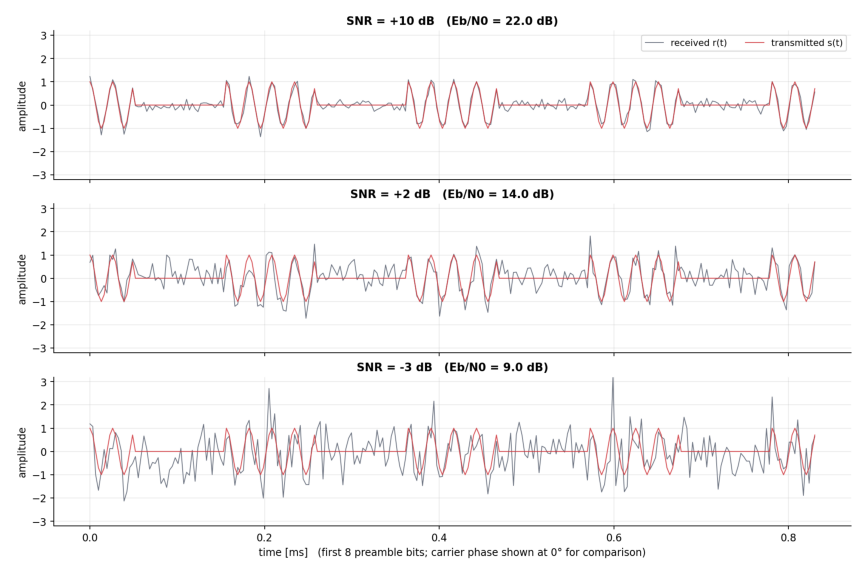

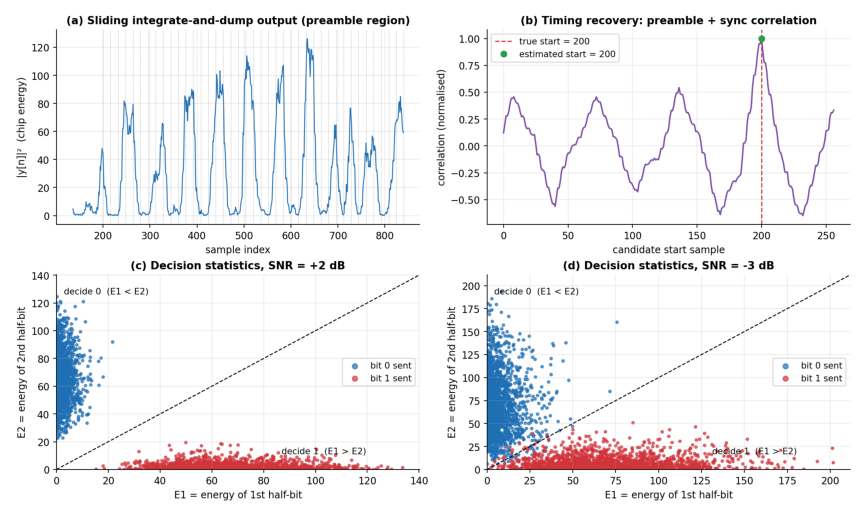

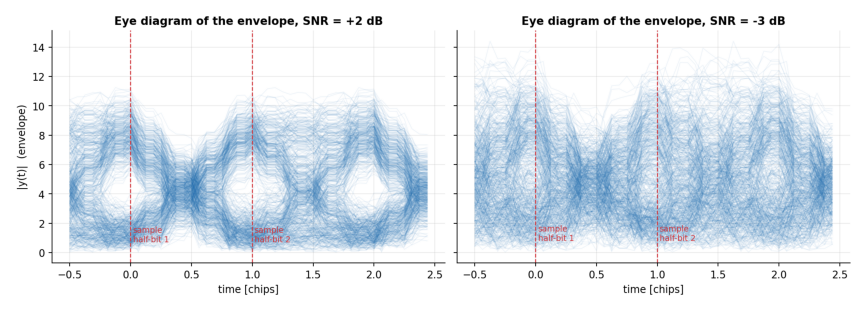

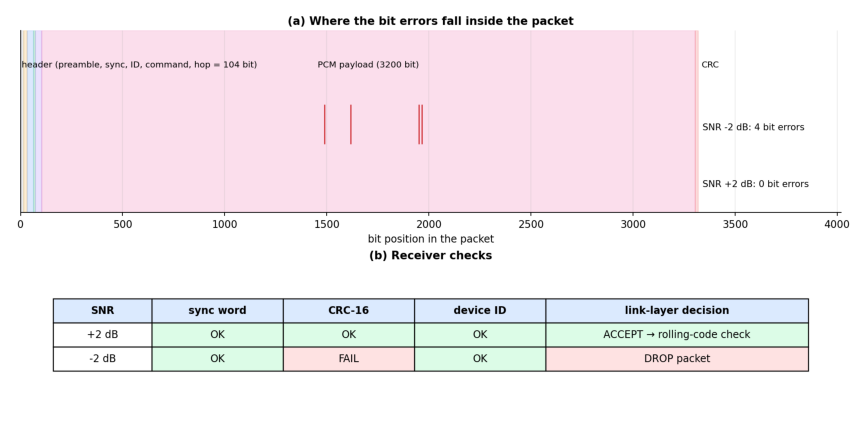

In [7]:
for snr in (2.0, -3.0):
    rx, leads, h, res, genie = run_link(tx.burst, tx.burst_q, cfg, snr, rng, n=1)
    n_err = int((res.bits[0] != tx.packet_bits).sum())
    print(f"SNR {snr:+.0f} dB: true start {leads[0]}, estimated {res.t0[0]}, bit errors {n_err}, "
          f"sync {bool(res.sync_ok[0])}, CRC {bool(res.crc_ok[0])}, ID {bool(res.id_ok[0])} -> accepted = {bool(res.accepted[0])}")
show("08_channel_received.png"); show("09_demodulation.png"); show("10_eye_diagram.png"); show("11_frame_parser.png")

## 4. Reconstruction
PCM decoder → mid-point levels → zero-order-hold D/A → 6th-order Butterworth low-pass.

SNR +2 dB: payload bit errors   0   MSE = 6.314e-06   reconstruction SNR =  49.0 dB
SNR -1 dB: payload bit errors   2   MSE = 8.762e-05   reconstruction SNR =  37.6 dB
SNR -3 dB: payload bit errors  25   MSE = 8.697e-03   reconstruction SNR =  17.6 dB
SNR -5 dB: payload bit errors 112   MSE = 3.799e-02   reconstruction SNR =  11.2 dB


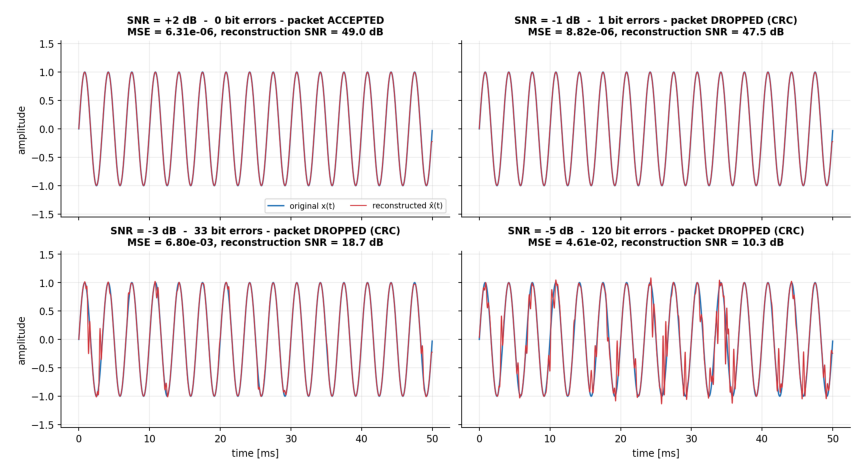

In [9]:
for snr in (2.0, -1.0, -3.0, -5.0):
    _, _, _, res, _ = run_link(tx.burst, tx.burst_q, cfg, snr, rng, n=1)
    xh = decode_payload(res.fields["payload"][0], cfg)
    m = mt.mse(tx.x_s, xh)
    print(f"SNR {snr:+.0f} dB: payload bit errors {(res.fields['payload'][0] != tx.pcm_bits).sum():3d}   "
          f"MSE = {m:.3e}   reconstruction SNR = {10*np.log10(p_x/m):5.1f} dB")
show("12_reconstruction.png")

## 5. Performance analysis (Monte-Carlo results from `main.py`)

 SNR dB  Eb/N0        BER    PSR    MSE raw  SNR_rec  MSE deliv.
   -6.0    6.0   6.71e-02  0.000   9.68e-02      7.1    5.00e-01
   -4.0    8.0   2.06e-02  0.000   2.77e-02     12.6    5.00e-01
   -2.0   10.0   3.23e-03  0.000   4.15e-03     20.8    5.00e-01
   -1.0   11.0   8.92e-04  0.048   1.22e-03     26.1    4.76e-01
    0.0   12.0   1.73e-04  0.585   2.15e-04     33.7    2.08e-01
    1.0   13.0   2.33e-05  0.927   3.58e-05     41.5    3.63e-02
    2.0   14.0   1.51e-06  0.993   1.26e-05     46.0    3.76e-03
    3.0   15.0   0.00e+00  1.000   6.31e-06     49.0    6.31e-06
    5.0   17.0   0.00e+00  1.000   6.31e-06     49.0    6.31e-06
   10.0   22.0   0.00e+00  1.000   6.31e-06     49.0    6.31e-06

90 % packet success at SNR = +0.9 dB (Eb/N0 = 13.0 dB, in-band 6.9 dB)
channel MSE = quantization MSE at BER = 4.7e-06  (Eb/N0 = 13.6 dB)


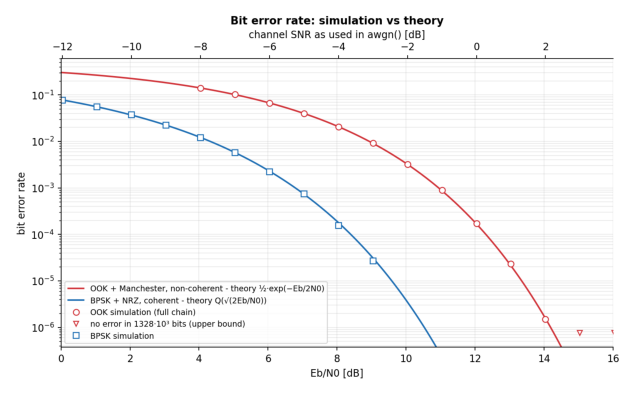

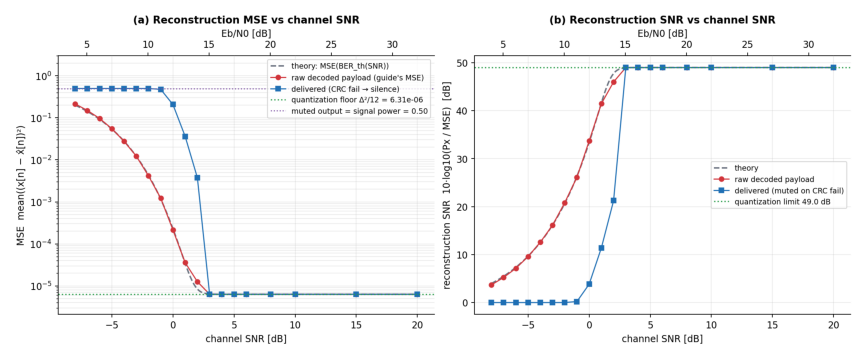

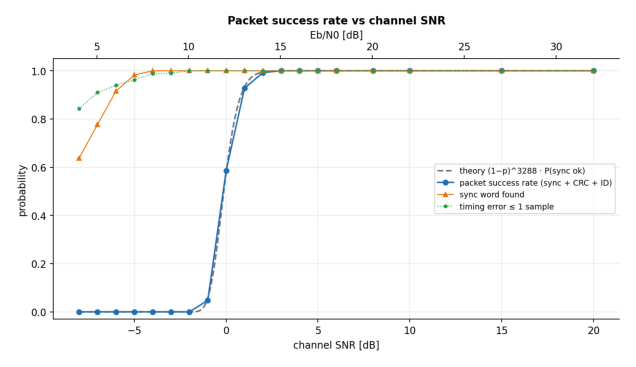

In [11]:
S = np.genfromtxt(ROOT / "results" / "sweep_snr.csv", delimiter=",", names=True)
print(f"{'SNR dB':>7} {'Eb/N0':>6} {'BER':>10} {'PSR':>6} {'MSE raw':>10} {'SNR_rec':>8} {'MSE deliv.':>11}")
for i in range(len(S)):
    if S['snr_db'][i] in (-6, -4, -2, -1, 0, 1, 2, 3, 5, 10):
        print(f"{S['snr_db'][i]:7.1f} {S['snr_db'][i]+12.04:6.1f} {S['ber_genie'][i]:10.2e} {S['psr'][i]:6.3f} "
              f"{S['mse_raw'][i]:10.2e} {10*np.log10(0.5/S['mse_raw'][i]):8.1f} {S['mse_delivered'][i]:11.2e}")
ss = M["sweep_summary"]
print()
print(f"90 % packet success at SNR = {ss['snr_psr90_db']:+.1f} dB (Eb/N0 = {ss['ebn0_psr90_db']:.1f} dB, in-band {ss['inband_psr90_db']:.1f} dB)")
print(f"channel MSE = quantization MSE at BER = {ss['p_star']:.1e}  (Eb/N0 = {ss['ebn0_star_db']:.1f} dB)")
show("13_ber_vs_snr.png", 8); show("14_mse_vs_snr.png"); show("15_psr_vs_snr.png", 8)

## 6. Shannon's channel-capacity theorem
`C = B log2(1 + SNR)` with the in-band SNR and `B = 4 Rb = 38.4 kHz`.

Shannon minimum in-band SNR for Rb = 9.6 kbit/s : -7.2 dB   (Eb/N0 >= -1.21 dB)
our link needs (90 % packets)                    : 6.9 dB   -> gap 14.2 dB
Eb/N0 for BER 1e-5: OOK 13.4 dB (gap 14.6 dB), BPSK 9.6 dB (gap 10.4 dB)
real-time PCM rate 64 kbit/s would need >= 3.4 dB in 38.4 kHz; fob rate is 9.6 kbit/s -> packets are buffered and sent as bursts


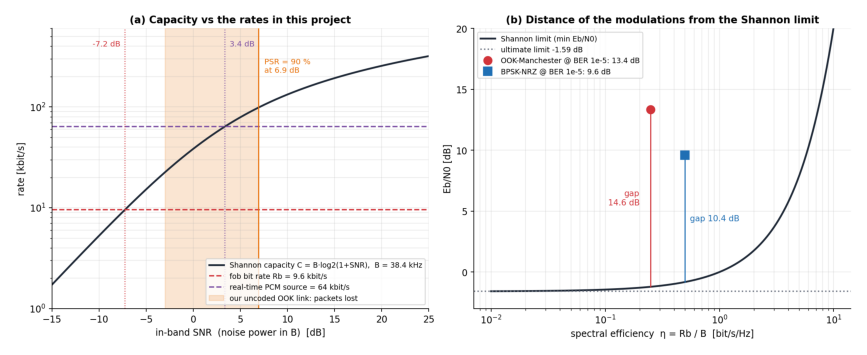

In [13]:
sh = M["shannon"]
print(f"Shannon minimum in-band SNR for Rb = 9.6 kbit/s : {sh['shannon_snr_b_db']:.1f} dB   (Eb/N0 >= {sh['shannon_ebn0_ook_db']:.2f} dB)")
print(f"our link needs (90 % packets)                    : {ss['inband_psr90_db']:.1f} dB   -> gap {ss['inband_psr90_db']-sh['shannon_snr_b_db']:.1f} dB")
print(f"Eb/N0 for BER 1e-5: OOK {sh['ook_req_ebn0_db']:.1f} dB (gap {sh['gap_ook_db']:.1f} dB), BPSK {sh['bpsk_req_ebn0_db']:.1f} dB (gap {sh['gap_bpsk_db']:.1f} dB)")
print(f"real-time PCM rate {sh['R_src']/1e3:.0f} kbit/s would need >= {sh['shannon_snr_b_src_db']:.1f} dB in 38.4 kHz; fob rate is {sh['Rb']/1e3:.1f} kbit/s -> packets are buffered and sent as bursts")
show("16_shannon.png")

## 7. Rolling-code security and range

1  owner     ACCEPT  - UNLOCK pressed next to the car  [valid rolling code]
2  attacker  REJECT  - recorded UNLOCK signal re-transmitted (replay attack)  [replay: counter already used]
3  owner     ACCEPT  - 3 presses out of range, then LOCK in range  [valid rolling code]
4  stranger  REJECT  - unpaired fob of another car  [ignored: device ID not paired with this car]
5  attacker  REJECT  - forged packet: sniffed ID, valid CRC, guessed hop code  [hop code failed authentication (forged / wrong key)]
6  owner     REJECT  - UNLOCK pressed at SNR = -6 dB (too noisy)  [dropped at link layer: sync word + CRC check failed]
7  owner     ACCEPT  - user presses again, link is good  [valid rolling code]
8  owner     REJECT  - 20 blind presses, then 1st press in range  [counter outside look-ahead window - press again to re-sync]
9  owner     ACCEPT  - 2nd consecutive press -> re-synchronisation  [re-synchronised (two consecutive counters)]

90 % packet-success range [m]:  AWGN 39.8   Rician 30.2  

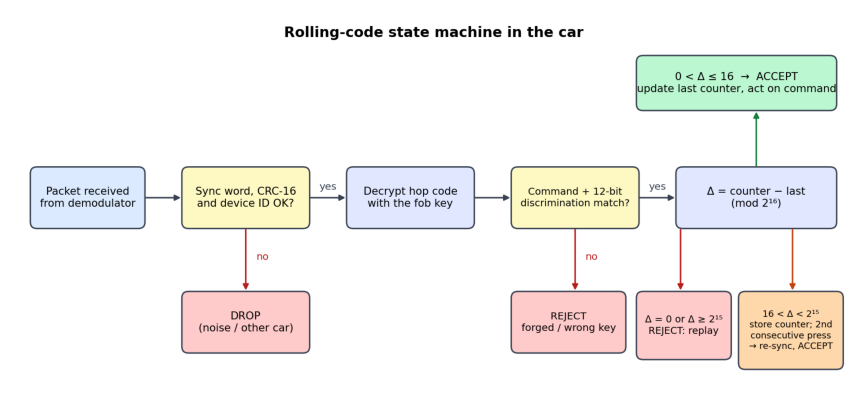

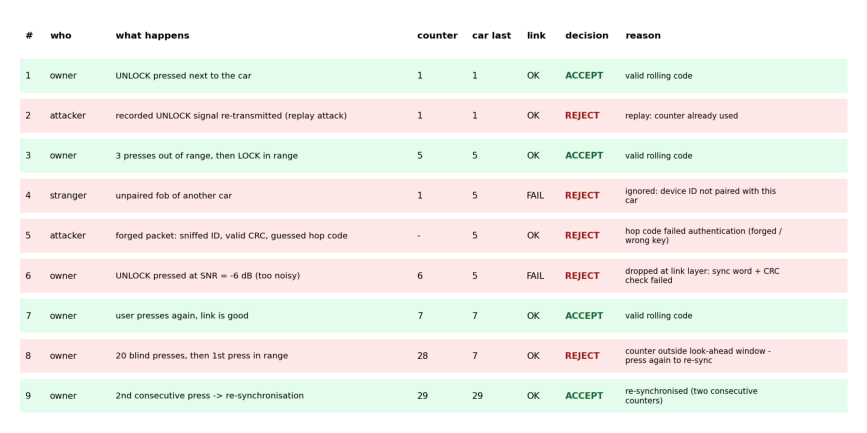

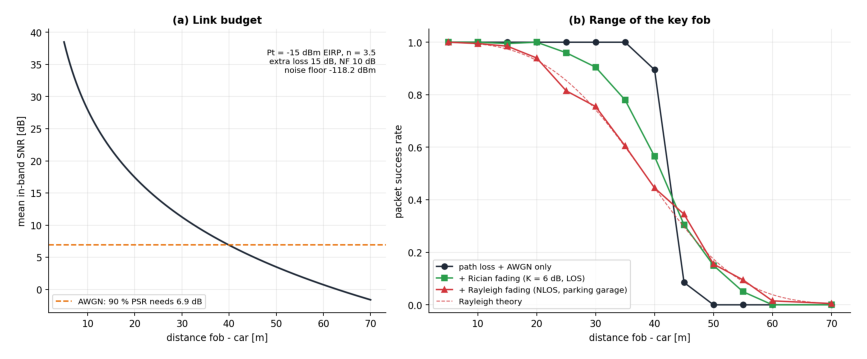

In [15]:
for e in M["security"]:
    print(f"{e['label']}  {e['who']:9s} {'ACCEPT' if e['accepted'] else 'REJECT'}  - {e['note']}  [{e['reason']}]")
show("17_rolling_code_flow.png"); show("18_security_demo.png")
d = M["distance"]
print()
print("90 % packet-success range [m]:  AWGN", round(d['range90_awgn'], 1), "  Rician", round(d['range90_rician'], 1), "  Rayleigh", round(d['range90_rayleigh'], 1))
show("19_distance_range.png")

## Conclusion
* Simulated BER matches theory for OOK-Manchester (non-coherent) and BPSK-NRZ (coherent).
* The MSE sits at the 8-bit quantization floor (≈ 49 dB reconstruction SNR) until the channel SNR approaches Eb/N0 ≈ 13-14 dB, then collapses within a few dB because a single MSB error costs as much as ≈ 400 quantization noises.
* At 90 % packet success the link is ≈ 14 dB from the Shannon limit: coding, not capacity, is the bottleneck; the source (8 bits) is the bottleneck at high SNR.
* The rolling code rejects replayed, forged and unpaired packets; fading cuts the useful range roughly in half.